In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl
import pyvista as pv
from desmin_reconstruction.plotting import save_panel
from desmin_reconstruction.plotting.overlays import compose_overlays, render_overlays
from desmin_reconstruction.plotting.renderings import (
    render_pointcloud,
)
from IPython.display import display, SVG
from desmin_reconstruction.preprocessing.bbox import BoundingSquare, filter_bounded
from dataclasses import dataclass
from itertools import product
from pathlib import Path
import csv

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

plt.rc("font", size=12)
plt.rc("grid", linestyle="--", color="lightgray")
plt.rc("axes.spines", right=False, top=False)
pv.set_jupyter_backend("static")

COLOR_DICT = {"desmin": "#CC3311", "actinin": "#009988"}

datadir = Path("../../data/")

In [2]:
def _corners(bounds):
    return np.asarray(list(product(*np.asarray(bounds).reshape(3, 2))), dtype=float)


def _default_edges(bounds):
    x0, x1, y0, y1, z0, z1 = bounds
    # Edges match the supplied view: X along the front bottom, Y along the
    # left top, and Z connecting their origins at the front-left corner.
    return {
        "x": np.array([[x0, y0, z0], [x1, y0, z0]]),
        "y": np.array([[x0, y0, z1], [x0, y1, z1]]),
        "z": np.array([[x0, y0, z0], [x0, y0, z1]]),
    }


def _grid_segments(bounds, ticks, camera_position, show_box):
    bounds = np.asarray(bounds).reshape(3, 2)
    center = bounds.mean(axis=1)
    # Draw grid planes on the side farthest from the camera. Because these
    # lines are 3D actors, the surfaces can occlude them naturally.
    back = np.where(np.asarray(camera_position[0]) >= center, bounds[:, 0], bounds[:, 1])
    segments = []
    for fixed in range(3):
        other = [a for a in range(3) if a != fixed]
        for tick_axis, line_axis in (other, other[::-1]):
            for value in ticks["xyz"[tick_axis]]:
                points = np.tile(back, (2, 1))
                points[:, fixed] = back[fixed]
                points[:, tick_axis] = value
                points[:, line_axis] = bounds[line_axis]
                segments.append(points)
    if show_box:
        for direction in range(3):
            other = [a for a in range(3) if a != direction]
            for values in product(*bounds[other]):
                points = np.zeros((2, 3))
                points[:, direction] = bounds[direction]
                points[:, other] = values
                segments.append(points)
    # Remove duplicate edges where grid planes meet.
    unique = {}
    for segment in segments:
        key = tuple(sorted(tuple(p) for p in segment))
        unique[key] = segment
    return np.asarray(list(unique.values()))


@dataclass
class RenderedLocalizationPanel:
    image: np.ndarray
    bounds: tuple
    scene_bounds: tuple
    ticks: dict
    world_to_clip: np.ndarray
    camera_position: tuple
    colors: dict
    probe_map: dict
    point_counts: dict

    def project(self, xyz):
        """World XYZ -> screenshot pixels, with Y increasing upward."""
        xyz = np.atleast_2d(np.asarray(xyz, dtype=float))
        clip = np.column_stack((xyz, np.ones(len(xyz)))) @ self.world_to_clip.T
        if np.any(clip[:, 3] <= 0):
            raise ValueError("A requested annotation lies behind the camera.")
        h, w = self.image.shape[:2]
        return (clip[:, :2]/clip[:, 3, None]+1)*np.array([w, h])/2


def list_probe_values(path, *, probe_column="probe"):
    """Return distinct probe values as strings, in first-appearance order.

    This order reproduces the ordering used in the original partition_by code;
    it does not identify which protein each probe represents.
    """
    with Path(path).open(newline="", encoding="utf-8-sig") as handle:
        reader = csv.DictReader(handle)
        if probe_column not in (reader.fieldnames or []):
            raise ValueError(f"CSV is missing {probe_column!r}.")
        values = dict.fromkeys(row[probe_column] for row in reader)
    return list(values)


def load_localizations(path, *, probe_map, bbox_xy=(6.0, 18.5, 0.0, 12.5),
                       coordinate_scale=1.0, xyz_columns=("x", "y", "z"),
                       probe_column="probe"):
    """Read two specified probes and retain points inside an inclusive XY ROI.

    probe_map maps protein name to its CSV probe value. Identifiers are compared
    as strings, so numeric values are accepted (e.g. 1 matches CSV '1'). Use the
    exact string returned by list_probe_values if the CSV stores '1.0'. Other
    probe values are ignored. An absent probe or an empty ROI raises an error.
    bbox_xy is in micrometers, after applying coordinate_scale to XYZ.
    Invalid coordinates in either selected channel raise an error.
    """
    proteins = ("desmin", "actinin")
    if set(probe_map) != set(proteins):
        raise ValueError("probe_map must have exactly 'desmin' and 'actinin' keys.")
    mapping = {name: str(probe_map[name]) for name in proteins}
    if len(set(mapping.values())) != 2:
        raise ValueError("Assign distinct probes to desmin and actinin.")
    roi = np.asarray(bbox_xy, dtype=float)
    if roi.shape != (4,) or not np.isfinite(roi).all() or np.any(roi[1::2] <= roi[::2]):
        raise ValueError("bbox_xy must be (xmin,xmax,ymin,ymax), with increasing pairs.")
    if not np.isfinite(coordinate_scale) or coordinate_scale <= 0:
        raise ValueError("coordinate_scale must be positive.")
    if len(xyz_columns) != 3 or len(set(xyz_columns)) != 3:
        raise ValueError("xyz_columns must specify three distinct column names.")
    inverse = {probe: name for name, probe in mapping.items()}
    collected = {name: [] for name in proteins}
    observed = set()
    x0, x1, y0, y1 = roi
    with Path(path).open(newline="", encoding="utf-8-sig") as handle:
        reader = csv.DictReader(handle)
        required = {probe_column, *xyz_columns}
        missing = required - set(reader.fieldnames or [])
        if missing:
            raise ValueError(f"CSV is missing columns: {sorted(missing)}.")
        for row_number, row in enumerate(reader, start=2):
            probe = row[probe_column]
            observed.add(probe)
            if probe not in inverse:
                continue
            try:
                xyz = tuple(float(row[c]) * coordinate_scale for c in xyz_columns)
            except (TypeError, ValueError) as error:
                raise ValueError(f"Invalid coordinate at CSV row {row_number}.") from error
            if not np.isfinite(xyz).all():
                raise ValueError(f"Nonfinite coordinate at CSV row {row_number}.")
            if x0 <= xyz[0] <= x1 and y0 <= xyz[1] <= y1:
                collected[inverse[probe]].append(xyz)
    for name in proteins:
        if mapping[name] not in observed:
            raise ValueError(f"Probe {mapping[name]!r} for {name} is absent; found {observed}.")
        if not collected[name]:
            raise ValueError(f"No {name} points inside bbox_xy={tuple(roi)}.")
    return {name: np.asarray(values, dtype=float) for name, values in collected.items()}


def render_localization_panel(
    csv_path, *, probe_map, bbox_xy=(6.0, 18.5, 0.0, 12.5),
    coordinate_scale=1.0, xyz_columns=("x", "y", "z"), probe_column="probe",
    colors=None, zlim=None,
    xticks=None, yticks=None, zticks=None,
    window_size=(1600, 1600), azimuth=230, elevation=10, zoom=1.0,
    camera_position=None, parallel_projection=False,
    point_size=5.0, opacity=0.2, emissive=False, anti_aliasing="ssaa",
    grid_color="#777777", grid_linewidth=0.7,
    show_grid=True, show_box=True,
):
    """Load and crop localizations; render Gaussian points without native labels.

    point_size=5 and opacity=0.2 reproduce the supplied Gaussian settings.
    No spheres or mesh lighting preset is imposed. Gaussian point_size is
    passed directly to PyVista, without scaling it by screenshot resolution.
    emissive=False uses non-emissive splats; True changes overlap brightness.
    zlim defaults to the retained points' Z range. A supplied zlim must include
    every retained point; it changes the frame, not the data. Flat-Z data need
    an explicit increasing zlim. Ticks default to five X/Y values and two Z
    values. Set anti_aliasing=None to keep the plotter's default antialiasing.

    Default camera: isometric start, azimuth=230 and elevation=10 degrees,
    perspective projection. For an exact match to an existing interactive
    view, pass camera_position=p.camera_position from that plot. This overrides
    azimuth/elevation/zoom. The returned object can be composed repeatedly.
    """
    import pyvista as pv

    colors = {**COLOR_DICT, **(colors or {})}
    if not np.isfinite(opacity) or not 0 <= opacity <= 1:
        raise ValueError("opacity must be between 0 and 1.")
    if not np.isfinite(point_size) or point_size <= 0:
        raise ValueError("point_size must be positive.")
    if anti_aliasing not in (None, "ssaa", "msaa", "fxaa"):
        raise ValueError("anti_aliasing must be None, 'ssaa', 'msaa' or 'fxaa'.")
    if not np.isfinite(zoom) or zoom <= 0:
        raise ValueError("zoom must be positive.")
    points = load_localizations(csv_path, probe_map=probe_map, bbox_xy=bbox_xy,
                                coordinate_scale=coordinate_scale,
                                xyz_columns=xyz_columns, probe_column=probe_column)
    meshes = {name: pv.PolyData(xyz) for name, xyz in points.items()}
    zmin = min(xyz[:, 2].min() for xyz in points.values())
    zmax = max(xyz[:, 2].max() for xyz in points.values())
    zlim = (zmin, zmax) if zlim is None else tuple(zlim)
    if len(zlim) != 2:
        raise ValueError("zlim must be (zmin,zmax).")
    limits = np.asarray((*bbox_xy, *zlim), dtype=float).reshape(3, 2)
    if not np.isfinite(limits).all() or np.any(limits[:, 1] <= limits[:, 0]):
        raise ValueError("XY bounds and zlim must contain finite increasing pairs.")
    if zlim[0] > zmin + 1e-9 or zlim[1] < zmax - 1e-9:
        raise ValueError(f"zlim must contain all retained Z values ({zmin:g}, {zmax:g}).")
    scene_bounds = limits.ravel()
    ticks = {}
    for axis, interval, supplied, count in zip("xyz", limits, (xticks, yticks, zticks), (5, 5, 2)):
        values = np.linspace(*interval, count) if supplied is None else np.asarray(supplied, dtype=float)
        if (values.ndim != 1 or values.size == 0 or not np.isfinite(values).all()
                or np.any(np.diff(values) <= 0) or values.min() < interval[0]-1e-9
                or values.max() > interval[1]+1e-9):
            raise ValueError(f"{axis}ticks must increase and lie within the displayed bounds.")
        ticks[axis] = values
    p = pv.Plotter(off_screen=True, window_size=window_size)
    try:
        if anti_aliasing is not None:
            p.enable_anti_aliasing(anti_aliasing)
        for name, mesh in meshes.items():
            p.add_mesh(mesh, color=colors[name], opacity=opacity,
                       style="points_gaussian", point_size=point_size,
                       emissive=emissive, render_points_as_spheres=False,
                       show_scalar_bar=False, reset_camera=False)
        p.set_background("black")
        if parallel_projection:
            p.enable_parallel_projection()
        else:
            p.disable_parallel_projection()
        if camera_position is None:
            p.view_isometric()
            # Use the complete frame for initial fitting, then retain the
            # original order of the user's azimuth/elevation adjustments.
            p.reset_camera(bounds=tuple(scene_bounds))
            p.camera.azimuth = azimuth
            p.camera.elevation = elevation
            p.camera.zoom(zoom)
        else:
            p.camera_position = camera_position
        cpos = tuple(tuple(v) for v in p.camera_position)
        segments = _grid_segments(limits.ravel(), ticks, cpos, show_box)
        if not show_grid:
            segments = _grid_segments(limits.ravel(), {a: [] for a in "xyz"}, cpos, show_box)
        if len(segments):
            wire_points = segments.reshape(-1, 3)
            connectivity = np.column_stack((np.full(len(segments), 2),
                                            np.arange(len(wire_points)).reshape(-1, 2))).ravel()
            wire = pv.PolyData(wire_points, lines=connectivity)
            p.add_mesh(wire, color=grid_color, line_width=grid_linewidth,
                       lighting=False, show_scalar_bar=False, reset_camera=False)
        p.reset_camera_clipping_range()
        rgb = np.array(p.screenshot(transparent_background=False), copy=True)
        m = p.camera.GetCompositeProjectionTransformMatrix(p.renderer.GetTiledAspectRatio(), -1, 1)
        matrix = np.array([[m.GetElement(i, j) for j in range(4)] for i in range(4)])
    finally:
        p.close()
    return RenderedLocalizationPanel(
        rgb, tuple(limits.ravel()), tuple(scene_bounds), ticks, matrix, cpos, colors,
        {name: str(value) for name, value in probe_map.items()},
        {name: len(xyz) for name, xyz in points.items()})


def compose_localization_panel(
    rendered, *, scene_width=3.6, figsize=None,
    margins=(1.20, 0.22, 0.58, 0.25),
    tick_fontsize=11, axis_fontsize=14, tick_format=".1f",
    tick_pads=None, label_pads=None, tick_rotations=None, label_rotations=None,
    tick_offsets=None, label_offsets=None,
    tick_length=3, axis_linewidth=0.8, axis_color="#DDDDDD",
    axis_edges=None, resolve_collisions=True, font_family="DejaVu Sans",
    image_padding_px=20,
):
    """Compose a calibrated raster scene with vector 3D axes and labels.

    scene_width, figsize and margins=(left,right,bottom,top) are inches.
    Padding, offsets, linewidths and tick_length are points. Font sizes are
    points. No 3D geometry or projected scale is stretched by the composition.

    tick_pads defaults to {'x':12, 'y':12, 'z':34}; Z numbers are separated
    from the Y-origin label. label_pads defaults to {'x':35,'y':35,'z':65}.
    tick_rotations defaults to projected X/Y directions, with horizontal Z
    numbers. Each can be overridden by a dict keyed 'x', 'y', 'z'.
    label_rotations similarly overrides the projected axis-title angles.
    tick_offsets accepts extra (dx,dy) point offsets keyed by (axis,index),
    e.g. {('z',0):(-3,-2)}. label_offsets accepts the same offsets per axis.

    resolve_collisions nudges crowded numeric labels outward using their
    rendered text bounds; tick marks remain at their exact projected positions.
    axis_edges optionally supplies two XYZ endpoints per axis for other views.
    The default edge choices reproduce the supplied azimuth/elevation view.
    image_padding_px keeps a small raster border around the projected frame,
    so Gaussian points centered near an ROI edge are not cut by the crop.
    """
    tick_pads = {"x": 12, "y": 12, "z": 34, **(tick_pads or {})}
    label_pads = {"x": 35, "y": 35, "z": 65, **(label_pads or {})}
    tick_offsets, label_offsets = tick_offsets or {}, label_offsets or {}
    edges = _default_edges(rendered.bounds) if axis_edges is None else axis_edges
    frame = rendered.project(_corners(rendered.scene_bounds))
    h, w = rendered.image.shape[:2]
    if not np.isfinite(image_padding_px) or image_padding_px < 1:
        raise ValueError("image_padding_px must be at least 1.")
    if np.any(frame < image_padding_px) or np.any(frame > np.array([w, h])-image_padding_px):
        raise ValueError("The scene touches the screenshot edge. Render again with a smaller zoom.")
    x0, y0 = np.floor(frame.min(axis=0)-image_padding_px)
    x1, y1 = np.ceil(frame.max(axis=0)+image_padding_px)
    image = rendered.image[h-int(y1):h-int(y0), int(x0):int(x1)]
    ratio = (y1-y0)/(x1-x0)
    left, right, bottom, top = map(float, margins)
    if min(left, right, bottom, top) < 0 or scene_width <= 0:
        raise ValueError("Margins must be nonnegative and scene_width positive.")
    if figsize is None:
        sw, sh = scene_width, scene_width*ratio
        fw, fh = left+sw+right, bottom+sh+top
        sx, sy = left, bottom
    else:
        fw, fh = map(float, figsize)
        available_w, available_h = fw-left-right, fh-bottom-top
        if min(available_w, available_h) <= 0:
            raise ValueError("figsize is too small for the margins.")
        sw = min(available_w, available_h/ratio)
        sh = sw*ratio
        sx, sy = left+(available_w-sw)/2, bottom+(available_h-sh)/2
    center = rendered.project(np.asarray(rendered.bounds).reshape(3, 2).mean(axis=1))[0]
    artists = {"ticks": {}, "labels": {}, "axis_lines": {}, "adjusted_ticks": []}
    with plt.style.context("default"), mpl.rc_context({"font.family": font_family,
              "figure.autolayout": False, "figure.constrained_layout.use": False}):
        fig = plt.figure(figsize=(fw, fh), facecolor="black")
        ax = fig.add_axes([sx/fw, sy/fh, sw/fw, sh/fh], facecolor="black")
        ax.imshow(image, extent=(x0,x1,y0,y1), origin="upper", aspect="equal", interpolation="none")
        ax.set_xlim(x0,x1)
        ax.set_ylim(y0,y1)
        ax.set_autoscale_on(False)
        ax.set_axis_off()
        raw_per_point = (x1-x0)/(sw*72)
        numeric = []
        normals = {}
        for i, axis in enumerate("xyz"):
            edge = np.asarray(edges[axis], dtype=float)
            if edge.shape != (2,3) or not np.isfinite(edge).all() or edge[1,i] <= edge[0,i]:
                raise ValueError(f"{axis}: supply two finite XYZ endpoints with increasing {axis}.")
            other = [j for j in range(3) if j != i]
            if not np.allclose(edge[0,other],edge[1,other]):
                raise ValueError(f"{axis}: its edge must vary only along {axis}.")
            projected = rendered.project(edge)
            tangent = projected[1]-projected[0]
            length = np.linalg.norm(tangent)
            if length < 1e-8:
                raise ValueError(f"{axis} axis is viewed end-on; choose a different camera.")
            tangent /= length
            normal = np.array([-tangent[1],tangent[0]])
            if normal @ (projected.mean(axis=0)-center) < 0:
                normal *= -1
            # Horizontal outward placement keeps the short Z ticks distinct.
            text_normal = np.array([-1.0,0.0]) if axis == "z" else normal
            normals[axis] = text_normal
            angle = (np.degrees(np.arctan2(tangent[1],tangent[0]))+90)%180-90
            rotation = (tick_rotations or {}).get(axis, 0.0 if axis == "z" else angle)
            label_angle = (label_rotations or {}).get(axis,
                np.degrees(np.arctan2(tangent[1], tangent[0])) if axis == "z" else angle)
            line, = ax.plot(*projected.T,color=axis_color,lw=axis_linewidth,clip_on=False,zorder=3)
            artists["axis_lines"][axis] = line
            for index, value in enumerate(rendered.ticks[axis]):
                point = edge[0].copy()
                point[i] = value
                q = rendered.project(point)[0]
                inner = q-normal*tick_length*raw_per_point
                ax.plot([q[0],inner[0]],[q[1],inner[1]],color=axis_color,
                        lw=axis_linewidth,clip_on=False,zorder=4)
                offset = text_normal*tick_pads[axis]+np.asarray(tick_offsets.get((axis,index),(0,0)))
                value = 0.0 if abs(value) < 1e-12 else value
                text = ax.annotate(format(value,tick_format),xy=q,xytext=offset,
                    textcoords="offset points",ha="center",va="center",
                    color="white",fontsize=tick_fontsize,rotation=rotation,
                    rotation_mode="anchor",annotation_clip=False,zorder=5)
                artists["ticks"][(axis,index)] = text
                numeric.append((axis,index,text))
            midpoint = rendered.project(edge.mean(axis=0))[0]
            offset = text_normal*label_pads[axis]+np.asarray(label_offsets.get(axis,(0,0)))
            text = ax.annotate(f"{axis} (μm)",xy=midpoint,xytext=offset,
                textcoords="offset points",ha="center",va="center",rotation=label_angle,
                rotation_mode="anchor",fontsize=axis_fontsize,color="white",
                annotation_clip=False,zorder=6)
            artists["labels"][axis] = text
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()
        if resolve_collisions:
            accepted = []
            # Keep the long-axis labels stable; resolve the short-axis crowding last.
            for axis,index,text in numeric:
                for attempt in range(51):
                    bbox = text.get_window_extent(renderer).padded(1.5*fig.dpi/72)
                    if not any(bbox.overlaps(b) for b in accepted):
                        break
                    text.set_position(np.asarray(text.get_position())+2*normals[axis])
                else:
                    plt.close(fig)
                    raise ValueError("Tick labels remain crowded. Increase scene_width or reduce tick_fontsize.")
                if attempt:
                    artists["adjusted_ticks"].append((axis,index))
                accepted.append(text.get_window_extent(renderer).padded(1.5*fig.dpi/72))
            for axis,text in artists["labels"].items():
                for attempt in range(51):
                    bbox = text.get_window_extent(renderer).padded(2*fig.dpi/72)
                    if not any(bbox.overlaps(b) for b in accepted):
                        break
                    text.set_position(np.asarray(text.get_position())+2*normals[axis])
                else:
                    plt.close(fig)
                    raise ValueError("Axis labels remain crowded. Increase scene_width or reduce axis_fontsize.")
                accepted.append(text.get_window_extent(renderer).padded(2*fig.dpi/72))
        # Keep full-canvas exports honest: report undersized margins explicitly.
        fig.canvas.draw()
        for text in [*artists["ticks"].values(),*artists["labels"].values()]:
            bbox = text.get_window_extent(fig.canvas.get_renderer())
            if bbox.x0 < 0 or bbox.y0 < 0 or bbox.x1 > fig.bbox.x1 or bbox.y1 > fig.bbox.y1:
                plt.close(fig)
                raise ValueError("Labels extend outside the canvas. Increase margins or figsize.")
    return fig, ax, artists


In [3]:
print(list_probe_values(datadir / "results/desmin_alphaactinin_600nm_aligned.csv"))

['0', '1']


In [12]:
rendered = render_localization_panel(
    datadir / "results/desmin_alphaactinin_600nm_aligned.csv",
    probe_map={"desmin": "0", "actinin": "1"},

    # Explicit order: xmin, xmax, ymin, ymax; units are μm.
    bbox_xy=(6.0, 18.5, 0.0, 12.5),
    coordinate_scale=1.0,  # Use 0.001 if CSV coordinates are in nm.

    point_size=1.5,
    opacity=0.2,
    window_size=(1600, 1600),

    azimuth=230,
    elevation=10,
    parallel_projection=False,

    # Defaults: five X/Y ticks and two Z ticks.
    # zlim=None uses the retained points' actual Z range.
)

In [15]:
fig, ax, artists = compose_localization_panel(
    rendered,
    figsize=(5.2, 4.3),                # Overall width, height in inches
    margins=(1.20, 0.22, 0.58, 0.25),  # Left, right, bottom, top—inches

    tick_fontsize=11,
    axis_fontsize=14,
    tick_format=".1f",

    # Distance from the projected axes, in points.
    tick_pads={"x": 12, "y": 12, "z": 34},
    label_pads={"x": 35, "y": 35, "z": 45},
    resolve_collisions=True,
)


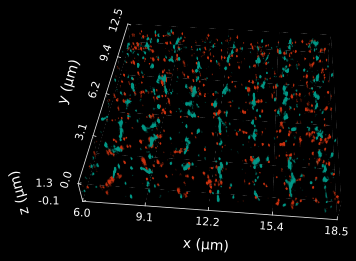

In [17]:
savepath = "../../figures/4e"
save_panel(fig, savepath, formats=("svg",))
display(SVG(filename=str(savepath + ".svg")))
plt.close(fig)